In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

Con la luminosidad (tomando $r_0 = 1$):
\begin{align*}
    L(r, \theta) = r^2  e^{-r} \sin{\theta} (1 + \cos{\theta})
\end{align*}
Y restricciones $\theta \in [0, \pi/2]$ y $r \in [0.1, 5]$.

El gradiente de esta función será:
\begin{align*}
    \nabla L(r, \theta) &=  (2r - r^2)e^{-r} \sin{\theta}(1 + \cos{\theta}) ~\hat{i} 
                            + r^2 e^{-r} [\cos{\theta}(1 + \cos{\theta}) - \sin^2{\theta}] ~\hat{j} \\[7pt]
    \nabla L(r, \theta) &=  (2r - r^2)e^{-r} \sin{\theta}(1 + \cos{\theta}) ~\hat{i} 
                            + r^2 e^{-r} (\cos{\theta} + \cos{2\theta}) ~\hat{j} \\[7pt]    
    \nabla L(r, \theta) &=  \frac{\partial L}{\partial r} ~\hat{i} 
                            + \frac{\partial L}{\partial \theta} ~\hat{j}   
\end{align*}

Se requiere también la función $g(h) = f(x_0 + hf_x, y_0 + hf_y)$ para minimizar $h$.
\begin{align*}
    r_0 + h \frac{\partial L}{\partial r} &= r_0 + h (2r - r^2)e^{-r} \sin{\theta} (1 + \cos{\theta}) \\[7pt]
    \theta_0 + h \frac{\partial L}{\partial \theta} &= \theta_0 + h r^2 e^{-r} (\cos\theta + \cos 2\theta)
\end{align*}

a) (1, π/6): r=2.0000, θ=60.00°, L=0.70322, iter=24
b) (3, π/4): r=2.0000, θ=60.00°, L=0.70322, iter=22
c) (0.5, π/3): r=2.0000, θ=60.00°, L=0.70322, iter=3


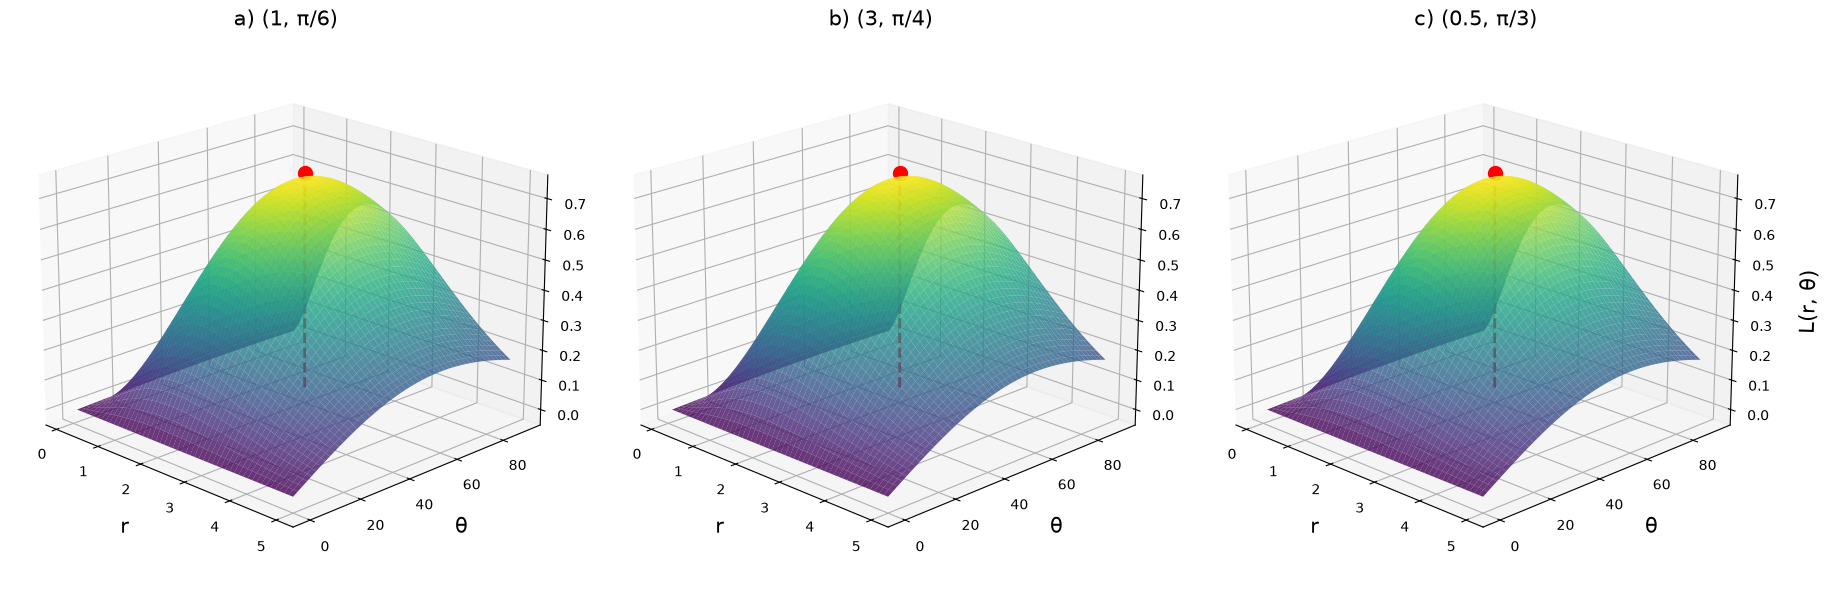

In [37]:
# FUNCIONES PRINCIPALES

# Luminosidad: f(x,y)
def luminosity(r, theta):
    return r**2 * np.exp(-r) * np.sin(theta) * (1 + np.cos(theta))

# Gradiente: Grad f(x,y)
def gradient(r, theta):
    dL_dr = (2*r - r**2) * np.exp(-r) * np.sin(theta) * (1 + np.cos(theta))
    dL_dtheta = r**2 * np.exp(-r) * (np.cos(theta) + np.cos(2*theta))
    return dL_dr, dL_dtheta

# Optimización Áurea de un parámetro para hallar h*
phi = (np.sqrt(5) - 1) / 2

def golden_max(f, a, b, tol=5e-2):
    x1 = b - phi * (b - a)
    x2 = a + phi * (b - a)
    f1, f2 = f(x1), f(x2)
    counter = 0
    while (b - a) > tol:
        if f1 < f2:
            a = x1
            x1, f1 = x2, f2
            x2 = a + phi * (b - a)
            f2 = f(x2)
        else:
            b = x2
            x2, f2 = x1, f1
            x1 = b - phi * (b - a)
            f1 = f(x1)
        counter += 1
    x = (a + b)/2
    return x, f(x), counter

# RESTRICCIONES IMPUESTAS:

r_win = [0.1, 5.0]
theta_win = [0.0, np.pi/2]

# GRADIENTE MULTIDIMENSIONAL

def optimization_gradient(x0, y0, x_win, y_win, func, gradient, tol=1e-6, max_iter=1000):

    x, y = x0, y0

    xmin, xmax = x_win[0], x_win[1]
    ymin, ymax = y_win[0], y_win[1]

    for i in range(1, max_iter + 1):
        dx, dy = gradient(x, y)

        # Mantener r y theta dentro de las ventanas impuestas
        if (x <= xmin and dx < 0) or (x >= xmax and dx > 0): dx = 0
        if (y <= ymin and dy < 0) or (y >= ymax and dy > 0): dy = 0

        norm = np.sqrt(dx**2 + dy**2)
        if norm < tol:
            return x, y, func(x,y), i

        # Determinar el h_min

        h_max = 1 / norm
        if   dx > 0: h_max = min(h_max, (xmax - x)/dx)
        elif dx < 0: h_max = min(h_max, (xmin - x)/dx)
        if   dy > 0: h_max = min(h_max, (ymax - y)/dy)
        elif dy < 0: h_max = min(h_max, (ymin - y)/dy)

        g = lambda h: func(x + h*dx, y + h*dy)

        h_min, _, _ = golden_max(g, 0, h_max, tol=0.05)

        x, y = x + h_min * dx, y + h_min * dy 

    print('Método no convergió.')
    return None, None, None, None


# SOLUCIÓN NUMÉRICA

func_start = [(1, np.pi/6), (3, np.pi/4), (0.5, np.pi/3)]
titles = ['a) (1, π/6)', 'b) (3, π/4)', 'c) (0.5, π/3)']
R = np.linspace(0.1, 5, 1000)
T = np.linspace(0, np.pi/2, 1000)
r, t = np.meshgrid(R, T)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), subplot_kw={'projection': '3d'})

for ax, (r0, theta0), title in zip(axes, func_start, titles):

    r_min, theta_min, L_max, n_iter  = optimization_gradient(r0, theta0, r_win, theta_win, luminosity, gradient)

    ax.plot_surface(r, np.degrees(t), luminosity(r, t), cmap='viridis', alpha=0.8)
    
    if theta_min is not None:
        ax.scatter(r_min, np.degrees(theta_min), luminosity(r_min, theta_min) + 0.02, color='r', s=100, depthshade=False, zorder=6)
        ax.plot([r_min, r_min], [np.degrees(theta_min), np.degrees(theta_min)], [0, L_max],'r--', linewidth=2)
        print(f'{title}: r={r_min:.4f}, θ={np.degrees(theta_min):.2f}°, L={L_max:.5f}, iter={n_iter}')   

    ax.set_title(f'{title}', fontsize=15)
    ax.set_xlabel('r', fontsize=15, labelpad=10); ax.set_ylabel('θ', fontsize=15, labelpad=10); ax.set_zlabel('L(r, θ)', fontsize=15, labelpad=10)
    ax.view_init(elev=20, azim=-45)


plt.tight_layout()
plt.show()